# Social Media Sentiment Analysis: A Comparative Study of Classical Machine Learning and Pretrained Transformer Models

A reproducible, research-style notebook comparing **TF-IDF + class-weighted linear classifiers** against the pretrained **`cardiffnlp/twitter-roberta-base-sentiment-latest`** transformer on the **Twitter US Airline Sentiment** dataset (Kaggle, CrowdFlower, CC BY-NC-SA 4.0).

## Abstract

Social-media sentiment analysis is difficult for unglamorous reasons: text is short, informal, ironic and class-imbalanced. This notebook runs a small, controlled experiment on a single documented dataset: a classical pipeline (TF-IDF features with class-weighted Logistic Regression, plus a Linear SVM baseline) and a pretrained transformer, fine-tuned by its authors on ~124M tweets and a TweetEval sentiment benchmark, are evaluated on **exactly the same held-out test examples** with the same label definitions and the same metrics (accuracy, macro precision/recall/F1, per-class scores, confusion matrices). The transformer is used *out of the box* — this project does not fine-tune it. The experiment is motivated by the author's MSc work on sentiment analysis in social media, but it is a **new implementation**: it does not reproduce, and makes no claims about, any prior dissertation's methodology, findings or results, and it makes **no claim of novelty**. Every number in this notebook is computed live by the cells below; nothing is hard-coded, and re-running reproduces (or updates) all results and figures.

## Objectives

1. Run a controlled comparison of a classical TF-IDF pipeline and a pretrained social-media transformer on **one shared held-out test set**, with all learned preprocessing fit on training data only.
2. Report class-aware metrics (macro-F1, per-class recall, confusion matrices) rather than headline accuracy alone, because the dataset is imbalanced (~63% negative).
3. Characterise *which* classes are confused (RQ2) and *what kinds of language* cause it (RQ3), with an exported error-analysis table.
4. Guarantee reproducibility: fixed seeds, recorded library versions and hardware, saved metrics (CSV), figures (PNG) and a packaged results archive (ZIP).

## How to run

`Runtime → Run all`. The notebook downloads the dataset automatically via `kagglehub` (the dataset is public — no credentials needed; if Kaggle credentials *are* configured they are used automatically) and falls back to clear manual-upload instructions if the download fails. It targets a **30–90 minute practical session on a Colab GPU runtime**, but actual runtime depends on hardware, download speeds and package versions; with no GPU it **automatically falls back to CPU** (slower transformer inference, identical logic). Estimated wall-clock: ~10–20 min on GPU, ~30–60 min on CPU for the transformer's test-set inference on this dataset size.


In [1]:
# 0.1 — Environment setup.
# Colab ships with most of these packages preinstalled; the guard below installs only
# what is missing, so this cell is fast to re-run and safe on a clean runtime.
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "numpy": "numpy>=2.0",
    "pandas": "pandas>=2.2",
    "sklearn": "scikit-learn>=1.5",
    "matplotlib": "matplotlib>=3.9",
    "torch": "torch>=2.4",
    "transformers": "transformers>=4.44",
    "kagglehub": "kagglehub>=0.3",
    "tqdm": "tqdm>=4.66",
}

missing = [spec for module, spec in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
else:
    print("All required packages are already available — nothing to install.")


All required packages are already available — nothing to install.


In [2]:
# 0.2 — Imports, reproducibility seeds, device detection and recorded versions.
import json
import os
import platform
import random
import re
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

def set_all_seeds(seed: int) -> None:
    # Seed every RNG the pipeline can touch. Transformer *inference* is deterministic
    # in eval mode regardless of seed; the seed pins the data split and the linear models.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_all_seeds(SEED)

RUN_STARTED_AT = datetime.now(timezone.utc).isoformat(timespec="seconds")

# Automatic CPU fallback: everything downstream uses this one device handle.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VERSIONS = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
}
HARDWARE = {
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "cpu_count": os.cpu_count(),
}

print("Versions:", json.dumps(VERSIONS, indent=2))
print("Hardware:", HARDWARE)


/root/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Versions: {
  "python": "3.11.17",
  "platform": "Linux-6.12.105+-aarch64-with-glibc2.36",
  "numpy": "2.4.6",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "torch": "2.14.1+cpu",
  "transformers": "5.20.1"
}
Hardware: {'device': 'cpu', 'gpu_name': None, 'cpu_count': 16}


In [3]:
# 0.3 — Configuration. Every design decision lives here so a reviewer can audit it.
DATASET_HANDLE = "crowdflower/twitter-airline-sentiment"
DATASET_URL = "https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment"
DATASET_LICENCE = "CC BY-NC-SA 4.0 (verified on the Kaggle dataset page: non-commercial use, attribution, share-alike)"

MODEL_ID = "cardiffnlp/twitter-roberta-base-sentiment-latest"
MODEL_CARD_URL = "https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest"

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
CSV_NAME = "Tweets.csv"
CSV_CANDIDATE_PATHS = [
    DATA_DIR / CSV_NAME,
    Path(CSV_NAME),
    Path("/content") / CSV_NAME,          # Colab manual-upload location
    Path("/content/data") / CSV_NAME,
]

MAX_LENGTH = 128                 # tweets are short; model card examples use 128
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 32
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.70, 0.15, 0.15
CANONICAL_LABELS = ["negative", "neutral", "positive"]   # matches the model's id2label order

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Seed:", SEED)
print("Device:", DEVICE, "| GPU:", HARDWARE["gpu_name"] or "none (CPU fallback)")
print("Transformer batch size:", BATCH_SIZE, "| max sequence length:", MAX_LENGTH)
print("Split fractions (train/val/test):", TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION)


Seed: 42
Device: cpu | GPU: none (CPU fallback)
Transformer batch size: 32 | max sequence length: 128
Split fractions (train/val/test): 0.7 0.15 0.15


## 2. Research questions

- **RQ1** — How does a TF-IDF-based classifier compare with a pretrained social-media transformer on the selected test dataset?
- **RQ2** — Which sentiment classes are most frequently confused by each model?
- **RQ3** — What kinds of social-media language lead to misclassification?

Where the evidence comes from:

| RQ | Evidence in this notebook |
|---|---|
| RQ1 | The comparison table and timing in §8–§9 (same held-out test set, same label definitions) |
| RQ2 | Confusion matrices in §8.2 |
| RQ3 | The error-analysis tables and exports in §10 |

The test split is used **exactly once**, for final evaluation. No thresholds, hyper-parameters or model choices are ever selected on it.


## 3. Background and motivation

**Classical sparse models.** Bag-of-words and TF-IDF features with linear classifiers have long been strong, cheap baselines for text classification; they train in seconds, are transparent, and remain hard to beat on small, in-domain datasets. `scikit-learn`'s TF-IDF + Logistic Regression is the canonical instance of this family (Pedregosa et al., 2011).

**Pretrained transformers.** Modern tweet NLP is dominated by models pretrained on very large Twitter corpora and then fine-tuned on small downstream tasks. The model used here, `cardiffnlp/twitter-roberta-base-sentiment-latest`, is a RoBERTa-base model trained on ~124M tweets (January 2018 – December 2021) and fine-tuned for three-class sentiment on the TweetEval benchmark (Barbieri et al., 2020; Loureiro et al., 2022). It is used **out of the box**: no parameters are updated in this notebook.

**Why compare them at all?** The interesting question for a practitioner is not "which is fashionable" but *how much* the pretrained representation buys on an imbalanced, informal, out-of-time domain (the tweets are from 2015; the transformer's pretraining corpus is 2018–2021). This notebook quantifies that gap on one documented dataset with a controlled protocol — and is equally interested in *where both models fail together*.

**Scope statement.** This is a new, small, controlled experiment inspired by the author's MSc dissertation topic ("Sentiment Analysis in Social Media"). It does **not** reproduce that dissertation's data, methodology or findings, and it claims no novelty of method or result.


## 4. Dataset and ethical considerations

**Source.** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) — 14,640 English tweets about major US airlines, posted in **February 2015**, scraped and then **crowd-labelled by CrowdFlower** workers as *negative*, *neutral* or *positive* (with a separate negative-reason taxonomy and a per-label confidence score, which this notebook does **not** use).

**Licence and usage terms (verified on the Kaggle dataset page at the time of writing).** The dataset is distributed under **CC BY-NC-SA 4.0**: **non-commercial** use, **attribution** required, **share-alike**. Practical consequences honoured by this project: the CSV is **not redistributed** with the notebook (it is downloaded from Kaggle or uploaded by the reader), the project is for research/education only, and the source is cited in §14 and in `CITATION.md`.

**Ethical considerations.**
- The tweets are public posts, but they are still personal expression: exported tables replace `@handles` with `@user` and URLs with `http`, and no re-identification is attempted.
- Crowd annotations carry the biases of the crowd (demographics, fatigue, platform familiarity); the `airline_sentiment_confidence` field that would quantify annotator certainty is unused here — a documented limitation (§12).
- The data reflects one platform (Twitter in 2015), one domain (US airlines) and one language (English); results must not be read as general statements about social-media sentiment (§12).
- No web-scraping is performed; only the published dataset is used.

**Acquisition policy (strict).** The notebook downloads the CSV automatically via `kagglehub` (anonymous download of this public dataset is supported; configured Kaggle credentials are used automatically if present). If the download fails, it looks for a manually uploaded `Tweets.csv`; if that is missing it **stops with explicit instructions** rather than silently substituting a different dataset.


In [4]:
# 4.1 — Dataset acquisition (kagglehub auto-download -> manual-upload fallback -> clear stop).
import hashlib

def sha256_of(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

csv_path = next((p for p in CSV_CANDIDATE_PATHS if p.exists()), None)
data_source_mode = None

if csv_path is None:
    print("No local CSV found — downloading from Kaggle via kagglehub ...")
    try:
        import kagglehub
        downloaded_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
        matches = list(downloaded_dir.rglob(CSV_NAME))
        if not matches:
            raise FileNotFoundError(f"{CSV_NAME} not found inside the downloaded folder: {downloaded_dir}")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        csv_path = DATA_DIR / CSV_NAME
        shutil.copyfile(matches[0], csv_path)
        data_source_mode = "automatic download (kagglehub)"
    except Exception as download_error:
        csv_path = next((p for p in CSV_CANDIDATE_PATHS if p.exists()), None)
        if csv_path is None:
            raise RuntimeError(
                "Could not obtain the dataset automatically.\n"
                f"Download failure: {download_error}\n"
                "\n"
                "Manual fallback (the dataset page hosts the CSV directly):\n"
                f"  1. Open {DATASET_URL} and click Download (a free Kaggle account is needed).\n"
                "  2. Unzip the archive and upload Tweets.csv into this notebook:\n"
                "       - Colab: open the Files sidebar and upload, so it lands at /content/Tweets.csv, or\n"
                f"       - any environment: place the file at {DATA_DIR / CSV_NAME}.\n"
                "  3. Re-run this cell.\n"
                "The notebook deliberately stops here instead of silently substituting a different dataset."
            ) from download_error
else:
    data_source_mode = "local CSV found at an expected path (uploaded or pre-provisioned)"

DATA_SHA256 = sha256_of(csv_path)
print(f"CSV file : {csv_path}  ({csv_path.stat().st_size / 1e6:.2f} MB)")
print(f"sha256   : {DATA_SHA256}")
print(f"Source   : {data_source_mode}")
print(f"Licence  : {DATASET_LICENCE}")


CSV file : data/Tweets.csv  (3.42 MB)
sha256   : ea94b23f41892b290dec3330bb8cf9cb6b8bc669eaae5f3a84c40f7b0de8f15e
Source   : local CSV found at an expected path (uploaded or pre-provisioned)
Licence  : CC BY-NC-SA 4.0 (verified on the Kaggle dataset page: non-commercial use, attribution, share-alike)


In [5]:
# 4.2 — Load the CSV, detect and validate the text/sentiment columns, profile the data.
try:
    raw_df = pd.read_csv(csv_path)
except Exception as read_error:
    raise RuntimeError(f"Failed to read {csv_path} as CSV: {read_error}") from read_error

if raw_df.empty:
    raise ValueError(f"{csv_path} contains no rows — the file is empty or truncated.")

def find_column(columns, candidates, role: str) -> str:
    lowered = {str(column).strip().lower(): column for column in columns}
    for candidate in candidates:
        if candidate in lowered:
            return lowered[candidate]
    raise ValueError(
        f"Could not detect the {role} column. Candidates tried: {candidates}. "
        f"Columns actually present: {list(raw_df.columns)}. If this is not the expected "
        "dataset, re-download it from the Kaggle page cited in §4."
    )

TEXT_COLUMN = find_column(raw_df.columns, ["text", "tweet", "tweet_text", "content", "message"], "text")
LABEL_COLUMN = find_column(raw_df.columns, ["airline_sentiment", "sentiment", "label", "target", "polarity", "class"], "sentiment")

labels_normalised = raw_df[LABEL_COLUMN].astype("string").str.strip().str.lower()
found_labels = sorted(labels_normalised.dropna().unique().tolist())
unexpected_labels = sorted(set(found_labels) - set(CANONICAL_LABELS))
if unexpected_labels:
    raise ValueError(
        f"The sentiment column {LABEL_COLUMN!r} contains unexpected values: {unexpected_labels}. "
        f"Expected a subset of {CANONICAL_LABELS}. The notebook does not guess label mappings — "
        "verify that you downloaded the intended dataset."
    )

# Three-class evaluation here; a binary subset of classes is also handled coherently:
# CLASS_ORDER collapses to the classes actually present, and results are reported for
# those classes only. Binary and three-class results are never presented as comparable.
CLASS_ORDER = [label for label in CANONICAL_LABELS if label in found_labels]
IS_THREE_CLASS = len(CLASS_ORDER) == 3

missing_text = int(raw_df[TEXT_COLUMN].isna().sum())
missing_label = int(raw_df[LABEL_COLUMN].isna().sum())
duplicate_rows = int(raw_df.duplicated().sum())

class_counts = labels_normalised.value_counts().reindex(CLASS_ORDER)
class_shares = (class_counts / class_counts.sum() * 100).round(1)
eda_summary = pd.DataFrame({"tweets": class_counts, "share_%": class_shares})

text_lengths = raw_df[TEXT_COLUMN].dropna().astype(str).str.split().str.len()

print(f"Rows: {len(raw_df):,} | Columns: {len(raw_df.columns)}")
print(f"Detected text column: {TEXT_COLUMN!r} | sentiment column: {LABEL_COLUMN!r}")
print(f"Classes detected: {found_labels} (three-class evaluation: {IS_THREE_CLASS})")
print(f"Missing text: {missing_text} | missing label: {missing_label} | fully duplicated rows: {duplicate_rows}")
print("\nClass balance (the dataset is strongly imbalanced toward 'negative'):")
display(eda_summary)
print("\nTweet length in words (overall):")
print(text_lengths.describe().round(1).to_string())


Rows: 14,640 | Columns: 15
Detected text column: 'text' | sentiment column: 'airline_sentiment'
Classes detected: ['negative', 'neutral', 'positive'] (three-class evaluation: True)
Missing text: 0 | missing label: 0 | fully duplicated rows: 36

Class balance (the dataset is strongly imbalanced toward 'negative'):


,tweets,share_%
airline_sentiment,,
negative,9178,62.7
neutral,3099,21.2
positive,2363,16.1



Tweet length in words (overall):
count    14640.0
mean        17.7
std          6.9
min          2.0
25%         12.0
50%         19.0
75%         23.0
max         36.0


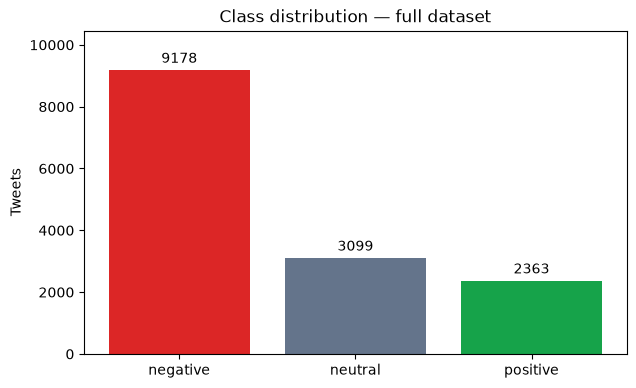

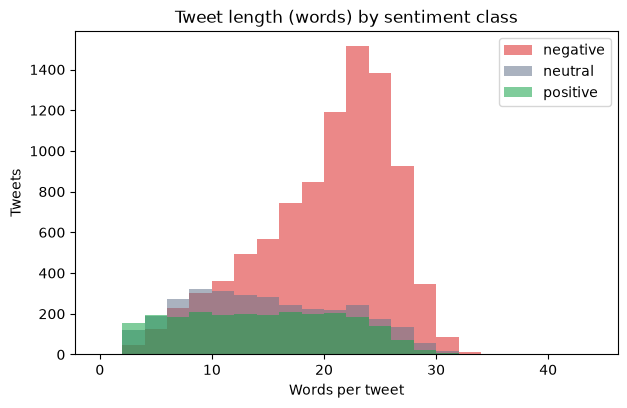

Saved: results/eda_summary.csv


In [6]:
# 4.3 — Class-balance and text-length figures (rendered here, saved to results/).
CLASS_COLORS = {"negative": "#dc2626", "neutral": "#64748b", "positive": "#16a34a"}

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(class_counts.index, class_counts.values, color=[CLASS_COLORS[c] for c in class_counts.index])
ax.bar_label(bars, padding=3)
ax.set_title("Class distribution — full dataset")
ax.set_ylabel("Tweets")
ax.set_ylim(0, class_counts.max() * 1.14)
fig.savefig(RESULTS_DIR / "fig_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2))
for label in CLASS_ORDER:
    ax.hist(text_lengths[labels_normalised == label], bins=range(0, 45, 2), alpha=0.55,
            label=label, color=CLASS_COLORS[label])
ax.set_title("Tweet length (words) by sentiment class")
ax.set_xlabel("Words per tweet")
ax.set_ylabel("Tweets")
ax.legend()
fig.savefig(RESULTS_DIR / "fig_text_lengths.png", dpi=150, bbox_inches="tight")
plt.show()

eda_summary.to_csv(RESULTS_DIR / "eda_summary.csv", index=True)
print("Saved:", RESULTS_DIR / "eda_summary.csv")


## 5. Experimental design

**Protocol.** One documented dataset, three models, **one shared held-out test set**, identical label definitions and metrics for every model. The test set is scored exactly once, in §8 — it is never used for tuning, threshold-setting or model choice.

**Split.** Stratified 70/15/15 train/validation/test with a fixed seed (`SEED = 42`), so every class keeps its proportion in each split. The validation split has exactly one job: selecting the Logistic Regression regularisation strength `C`. Nothing else touches it.

**Models.**

| Model | Input | Fit in this notebook? | Tuning |
|---|---|---|---|
| A1 — TF-IDF + Logistic Regression | TF-IDF, 1–2 grams, sublinear TF, min_df 2, max_df 0.95 | yes — fit on the train split, class-weighted | `C` ∈ {0.25, 0.5, 1, 2, 4} chosen on **validation** macro-F1 |
| A2 — TF-IDF + Linear SVM | same TF-IDF matrix | yes — fit on the train split, class-weighted | none (default `C=1.0`; secondary baseline) |
| B — RoBERTa-base (`cardiffnlp/twitter-roberta-base-sentiment-latest`) | model-card-normalised text | **no** — used out of the box, pretrained + fine-tuned by its authors | none |

**Label-mapping policy.** The transformer's `id2label` mapping is *inspected and asserted* at load time (§7.2), never assumed. On this dataset all three classes (`negative`, `neutral`, `positive`) exist on both sides, so all three are evaluated consistently. If the data had contained only two classes, `CLASS_ORDER` would collapse to the classes actually present and results would be reported for those classes only — **binary and three-class results are never presented as comparable**.

**Leakage prevention.**
- The TF-IDF vocabulary and IDF weights are fit on the **training split only**.
- `C` is selected on the **validation split only**.
- The test split is transformed/predicted **once**, in §8.
- The split is stratified on labels and asserted **text-disjoint** — each unique tweet text appears in exactly one split.

**Metrics.** Accuracy; macro precision/recall/F1 (§8 explains why macro matters here); per-class precision/recall/F1 with support; confusion matrices; wall-clock inference time on the recorded device. No benchmark-style metric beyond these is reported, so no special definitions or citations are needed.


## 6. Preprocessing

**Preserved untouched:** the original tweet text (`text_raw`) — every export and every display traces back to it.

**What is done, and only what is necessary:**

1. **Working frame** — rows with missing/empty text or label are dropped (counted, not hidden). The dataset repeats a few hundred records, and a small number of texts carry **conflicting** crowd labels (annotators disagreed); every text is reduced to one row — first occurrence kept, conflicting-label rows counted and reported. One row per unique text is what makes the text-level disjointness of the splits assertable (§5).
2. **Whitespace collapse** — the only cleaning applied to the classical features. No lowercasing (capitalisation carries signal: "GREAT…"), no stopword removal ("not" is the point), no stemming, no emoji stripping (emoji are strong sentiment markers). TF-IDF's sublinear term frequency handles most of what aggressive cleaning pretends to fix.
3. **Transformer input normalisation** — the model card instructs replacing usernames with `@user` and links with `http` before tokenisation; §7.3 implements exactly that, for the transformer's input only.
4. **Fit on train only** — the TF-IDF vectoriser learns vocabulary and IDF weights from the training split; validation/test are *transformed* with the frozen vectoriser.

**A note on the asymmetry.** The two models receive different surface forms of the same tweets: whitespace-collapsed raw text for TF-IDF, model-card-normalised text for the transformer. This is deliberate: each model gets the input its documentation specifies, so the comparison is between two *correctly configured complete systems*, not between arbitrary text variants. The asymmetry is revisited as a threat to validity in §12.


In [7]:
# 6.1 — Build the working frame, then the reproducible stratified split.
text_series = raw_df[TEXT_COLUMN]
work = pd.DataFrame({
    "tweet_id": raw_df["tweet_id"].astype(str) if "tweet_id" in raw_df.columns else [str(i) for i in range(len(raw_df))],
    "text_raw": text_series,
    "label": labels_normalised,
})

before = len(work)
work = work.dropna(subset=["text_raw", "label"])
work = work[work["text_raw"].astype(str).str.strip() != ""]
work["text_raw"] = work["text_raw"].astype(str)
after_missing = len(work)

# One row per unique text, first occurrence kept. This dataset repeats a few hundred
# records and some texts carry conflicting crowd labels (annotator disagreement);
# the first label wins and the discarded rows are counted below. Two raw texts can
# also differ only in whitespace — the collapsed form is what both models effectively
# see, so deduplication finishes on the collapsed text. One row per unique text is
# what makes the text-disjointness of the splits assertable.
label_conflicts = int((work.groupby("text_raw")["label"].nunique() > 1).sum())
work = work.drop_duplicates(subset=["text_raw"])
work["text_clean"] = work["text_raw"].str.replace(r"\s+", " ", regex=True).str.strip()
work = work.drop_duplicates(subset=["text_clean"]).reset_index(drop=True)
after = len(work)
print(f"Rows removed: {before - after:,} total — {before - after_missing:,} missing/empty text or label, {after_missing - after:,} duplicate texts.")
print(f"  (the duplicates include {label_conflicts} texts with conflicting crowd labels; first label kept)")
print(f"{after:,} unique texts retained.")

train_df, temp_df = train_test_split(
    work, test_size=VAL_FRACTION + TEST_FRACTION, stratify=work["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=TEST_FRACTION / (VAL_FRACTION + TEST_FRACTION), stratify=temp_df["label"], random_state=SEED,
)
for frame in (train_df, val_df, test_df):
    frame.reset_index(drop=True, inplace=True)

split_rows = []
for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    counts = frame["label"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
    split_rows.append([name, len(frame), *counts.tolist()])
split_summary = pd.DataFrame(split_rows, columns=["split", "n", *CLASS_ORDER])
display(split_summary)

assert not (set(train_df["text_clean"]) & set(test_df["text_clean"])), "train/test text leakage detected"
assert not (set(train_df["text_clean"]) & set(val_df["text_clean"])), "train/val text leakage detected"
assert not (set(val_df["text_clean"]) & set(test_df["text_clean"])), "val/test text leakage detected"
print(f"Split sizes: train={len(train_df):,}  validation={len(val_df):,}  test={len(test_df):,} — stratified, text-disjoint (asserted).")
print("The test split will be used exactly once: final evaluation in §8.")
split_summary.to_csv(RESULTS_DIR / "split_summary.csv", index=False)


Rows removed: 216 total — 0 missing/empty text or label, 216 duplicate texts.
  (the duplicates include 25 texts with conflicting crowd labels; first label kept)
14,424 unique texts retained.


,split,n,negative,neutral,positive
0,train,10096,6356,2139,1601
1,validation,2164,1362,458,344
2,test,2164,1362,459,343


Split sizes: train=10,096  validation=2,164  test=2,164 — stratified, text-disjoint (asserted).
The test split will be used exactly once: final evaluation in §8.


## 7. Model implementation

**Model A — classical.** TF-IDF (word unigrams + bigrams, sublinear TF, `min_df=2` drops hapax-legomena, `max_df=0.95` drops corpus-ubiquitous tokens) followed by:
- **A1 — Logistic Regression** with `class_weight="balanced"` (the 63/21/16% class skew would otherwise dominate the loss), L-BFGS, and regularisation `C` selected from {0.25, 0.5, 1, 2, 4} by **validation** macro-F1.
- **A2 — Linear SVM** (`LinearSVC`, class-weighted, default `C=1.0`) as a secondary, deliberately untuned linear baseline.

**Model B — pretrained transformer.** `cardiffnlp/twitter-roberta-base-sentiment-latest` (RoBERTa-base; ~125M parameters), loaded in eval mode and executed under `torch.inference_mode()` with per-device batching, truncation to 128 tokens and per-batch padding. **No fine-tuning is performed** — the model's weights are exactly as published by Cardiff NLP (trained on ~124M tweets, 2018–2021; fine-tuned on the TweetEval sentiment benchmark). Its `id2label` mapping is printed and asserted against the dataset's classes before any inference.


In [8]:
# 7.1 — Model A: TF-IDF (fit on train ONLY) + class-weighted linear classifiers.
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

vectoriser = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
X_train_vec = vectoriser.fit_transform(train_df["text_clean"])   # fit on TRAIN only
X_val_vec = vectoriser.transform(val_df["text_clean"])           # transform, never re-fit
print(f"TF-IDF: {X_train_vec.shape[0]:,} train documents x {X_train_vec.shape[1]:,} features")

# C selected on the VALIDATION split only — the test split is not touched here.
c_grid = [0.25, 0.5, 1.0, 2.0, 4.0]
c_rows = []
for c_value in c_grid:
    candidate = LogisticRegression(C=c_value, class_weight="balanced", max_iter=2000, random_state=SEED)
    candidate.fit(X_train_vec, y_train)
    c_rows.append({"C": c_value, "val_macro_f1": round(f1_score(y_val, candidate.predict(X_val_vec), average="macro"), 4)})

c_sweep = pd.DataFrame(c_rows)
display(c_sweep)
BEST_C = float(c_sweep.loc[c_sweep["val_macro_f1"].idxmax(), "C"])   # ties -> smallest C
print(f"Selected C={BEST_C} (highest validation macro-F1).")
c_sweep.to_csv(RESULTS_DIR / "c_sweep_validation.csv", index=False)

lr_clf = LogisticRegression(C=BEST_C, class_weight="balanced", max_iter=2000, random_state=SEED).fit(X_train_vec, y_train)
svm_clf = LinearSVC(class_weight="balanced", max_iter=20000, random_state=SEED).fit(X_train_vec, y_train)
print("Model A fitted: Logistic Regression (class-weighted, C on validation) and Linear SVM (class-weighted, default C).")


TF-IDF: 10,096 train documents x 22,302 features


,C,val_macro_f1
0,0.25,0.7305
1,0.50,0.7352
2,1.00,0.7393
3,2.00,0.7488
4,4.00,0.7455


Selected C=2.0 (highest validation macro-F1).


Model A fitted: Logistic Regression (class-weighted, C on validation) and Linear SVM (class-weighted, default C).


In [9]:
# 7.2 — Model B: load the pretrained transformer and INSPECT its label mapping before use.
from transformers import AutoConfig, AutoModelForSequenceClassification, AutoTokenizer

print(f"Loading {MODEL_ID} on {DEVICE} ...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
config = AutoConfig.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,} | mode: eval (no fine-tuning)")

# Never assume the label order — read it from the config (the model card documents
# {0: negative, 1: neutral, 2: positive}) and assert it against the dataset's classes.
print("config.id2label as shipped:", config.id2label)
MODEL_ID2LABEL = {int(index): str(name).strip().lower() for index, name in dict(config.id2label).items()}
if set(MODEL_ID2LABEL.values()) != set(CLASS_ORDER):
    raise RuntimeError(
        f"Label-mapping mismatch: the model outputs {sorted(MODEL_ID2LABEL.values())} but the "
        f"dataset provides {CLASS_ORDER}. Per the model card, do not invent a mapping — choose a "
        "documented model whose labels match, or restrict evaluation to the shared classes and "
        "document the restriction (§5)."
    )
MODEL_INDEX = {name: index for index, name in MODEL_ID2LABEL.items()}
INDEX2NAME = {index: name for name, index in MODEL_INDEX.items()}
print("Validated mapping — canonical class -> model output index:", MODEL_INDEX)
print("Provenance: trained on ~124M tweets (01/2018-12/2021), fine-tuned on the TweetEval sentiment benchmark by Cardiff NLP.")


Loading cardiffnlp/twitter-roberta-base-sentiment-latest on cpu ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 20340.56it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Parameters: 124,647,939 | mode: eval (no fine-tuning)
config.id2label as shipped: {0: 'negative', 1: 'neutral', 2: 'positive'}
Validated mapping — canonical class -> model output index: {'negative': 0, 'neutral': 1, 'positive': 2}
Provenance: trained on ~124M tweets (01/2018-12/2021), fine-tuned on the TweetEval sentiment benchmark by Cardiff NLP.


In [10]:
# 7.3 — Model-card normalisation and batched inference (device-aware, no_grad path).
# The model card instructs replacing usernames with '@user' and links with 'http'
# before tokenisation. Applied to transformer inputs only; raw text is untouched.
def normalise_for_cardiff(text: str) -> str:
    tokens = []
    for token in text.split(" "):
        if token.startswith("@") and len(token) > 1:
            token = "@user"
        elif token.startswith("http"):
            token = "http"
        tokens.append(token)
    return " ".join(tokens)

@torch.inference_mode()
def predict_transformer(texts, batch_size: int = BATCH_SIZE):
    probabilities = []
    for start in tqdm(range(0, len(texts), batch_size), desc="transformer inference", leave=False):
        batch = [normalise_for_cardiff(text) for text in texts[start : start + batch_size]]
        encoded = tokenizer(
            batch, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt",
        ).to(DEVICE)
        logits = model(**encoded).logits
        probabilities.append(torch.nn.functional.softmax(logits, dim=-1).detach().cpu().numpy())
    return np.concatenate(probabilities, axis=0)   # columns follow MODEL_INDEX indices

# Smoke test on validation texts (never the test split): shapes, mapping and speed.
_smoke = val_df["text_raw"].head(8).tolist()
_smoke_probs = predict_transformer(_smoke)
assert _smoke_probs.shape == (8, len(CLASS_ORDER)), f"unexpected output shape {_smoke_probs.shape}"
print("Smoke test — predicted:", [INDEX2NAME[i] for i in _smoke_probs.argmax(axis=1)])


transformer inference:   0%|          | 0/1 [00:00<?, ?it/s]

transformer inference: 100%|██████████| 1/1 [00:04<00:00,  4.52s/it]

Smoke test — predicted: ['negative', 'negative', 'negative', 'negative', 'negative', 'negative', 'negative', 'negative']


## 8. Evaluation metrics

Every model is scored on **the same test examples** with the same definitions:

- **Accuracy** — the share of exactly-correct predictions. Reportable, but misleading alone here: the majority class (*negative*, ~63%) sets a high trivial baseline, so §9 emphasises macro-F1.
- **Macro precision / recall / F1** — the **unweighted mean of the per-class metrics** over the three classes. Because macro averaging weights every class equally regardless of frequency, it exposes weakness on the minority *neutral*/*positive* classes that accuracy hides.
- **Per-class precision / recall / F1 with support** — the class-level view that answers RQ2 alongside the confusion matrix.
- **Confusion matrix** — rows are true classes, columns are predicted classes; counts and row-shares are both annotated in §8.2.
- **Classification report** — the full per-class table, printed and saved as text per model.
- **Inference time** — wall-clock around the complete prediction path (featurisation/tokenisation + prediction) for all test examples, on the recorded device. Timing is hardware-dependent and reported for transparency, not as a quality metric.

**Confidence ≠ calibrated probability.** The confidence analysis in §9 reports raw outputs (softmax for the transformer, `predict_proba` for Logistic Regression). These are *uncalibrated*: a 0.9 score is **not** a 90% probability of correctness (no temperature scaling or other calibration is applied). The SVM is excluded from confidence analysis — `LinearSVC` outputs margin distances, not probabilities.


In [11]:
# 8.1 — Final evaluation on the shared held-out TEST set (its single use in this notebook).
t0 = time.perf_counter()
X_test_vec = vectoriser.transform(test_df["text_clean"])
y_pred_lr = lr_clf.predict(X_test_vec)
seconds_lr = time.perf_counter() - t0

t0 = time.perf_counter()
X_test_vec_svm = vectoriser.transform(test_df["text_clean"])
y_pred_svm = svm_clf.predict(X_test_vec_svm)
seconds_svm = time.perf_counter() - t0

t0 = time.perf_counter()
probs_tx = predict_transformer(test_df["text_raw"].tolist())
seconds_tx = time.perf_counter() - t0
y_pred_tx = np.array([INDEX2NAME[i] for i in probs_tx.argmax(axis=1)])

def evaluate_model(model_name, model_slug, y_pred, seconds):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    per_p, per_r, per_f1, per_s = precision_recall_fscore_support(
        y_test, y_pred, labels=CLASS_ORDER, average=None, zero_division=0,
    )
    return {
        "model": model_name,
        "slug": model_slug,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "n_test": len(y_test),
        "seconds": seconds,
        "examples_per_second": len(y_test) / seconds,
        "device": str(DEVICE),
        "per_class": pd.DataFrame({"class": CLASS_ORDER, "precision": per_p, "recall": per_r, "f1": per_f1, "support": per_s}),
        "confusion_matrix": confusion_matrix(y_test, y_pred, labels=CLASS_ORDER),
        "report": classification_report(y_test, y_pred, labels=CLASS_ORDER, digits=4, zero_division=0),
    }

results = {
    "TF-IDF + Logistic Regression": evaluate_model("TF-IDF + Logistic Regression", "logreg", y_pred_lr, seconds_lr),
    "TF-IDF + Linear SVM": evaluate_model("TF-IDF + Linear SVM", "svm", y_pred_svm, seconds_svm),
    "RoBERTa (cardiffnlp, pretrained)": evaluate_model("RoBERTa (cardiffnlp, pretrained)", "roberta", y_pred_tx, seconds_tx),
}

comparison = pd.DataFrame(
    [{key: value for key, value in result.items() if key not in ("per_class", "confusion_matrix", "report", "slug")}
     for result in results.values()]
).round(4)
display(comparison)
comparison.to_csv(RESULTS_DIR / "comparison_metrics.csv", index=False)

per_class_all = pd.concat([result["per_class"].assign(model=name) for name, result in results.items()])
display(per_class_all.round(4))
per_class_all.to_csv(RESULTS_DIR / "per_class_metrics.csv", index=False)

comparison[["model", "seconds", "examples_per_second", "device"]].to_csv(RESULTS_DIR / "inference_timing.csv", index=False)

for name, result in results.items():
    (RESULTS_DIR / f"classification_report_{result['slug']}.txt").write_text(result["report"])
    print(f"=== {name} ===")
    print(result["report"])


transformer inference:   0%|          | 0/68 [00:00<?, ?it/s]

transformer inference:   1%|▏         | 1/68 [00:09<10:46,  9.65s/it]

transformer inference:   3%|▎         | 2/68 [00:16<08:42,  7.91s/it]

transformer inference:   4%|▍         | 3/68 [00:22<07:40,  7.09s/it]

transformer inference:   6%|▌         | 4/68 [00:29<07:28,  7.01s/it]

...

transformer inference:  99%|█████████▊| 67/68 [07:30<00:06,  6.78s/it]

transformer inference: 100%|██████████| 68/68 [07:34<00:00,  6.04s/it]

,model,accuracy,macro_precision,macro_recall,macro_f1,n_test,seconds,examples_per_second,device
0,TF-IDF + Logistic Regression,0.8036,0.7511,0.7636,0.7561,2164,0.0517,41849.4850,cpu
1,TF-IDF + Linear SVM,0.8110,0.7670,0.7441,0.7544,2164,0.0392,55253.5575,cpu
2,"RoBERTa (cardiffnlp, pretrained)",0.7754,0.7160,0.7865,0.7397,2164,454.8552,4.7576,cpu


,class,precision,recall,f1,support,model
0,negative,0.8939,0.8539,0.8735,1362,TF-IDF + Logistic Regression
1,neutral,0.6243,0.7168,0.6673,459,TF-IDF + Logistic Regression
2,positive,0.7351,0.7201,0.7275,343,TF-IDF + Logistic Regression
0,negative,0.8703,0.8965,0.8832,1362,TF-IDF + Linear SVM
1,neutral,0.6508,0.6536,0.6522,459,TF-IDF + Linear SVM
2,positive,0.7800,0.6822,0.7278,343,TF-IDF + Linear SVM
0,negative,0.9454,0.7761,0.8524,1362,"RoBERTa (cardiffnlp, pretrained)"
1,neutral,0.5310,0.6710,0.5929,459,"RoBERTa (cardiffnlp, pretrained)"
2,positive,0.6717,0.9125,0.7738,343,"RoBERTa (cardiffnlp, pretrained)"


=== TF-IDF + Logistic Regression ===
              precision    recall  f1-score   support

    negative     0.8939    0.8539    0.8735      1362
     neutral     0.6243    0.7168    0.6673       459
    positive     0.7351    0.7201    0.7275       343

    accuracy                         0.8036      2164
   macro avg     0.7511    0.7636    0.7561      2164
weighted avg     0.8116    0.8036    0.8066      2164

=== TF-IDF + Linear SVM ===
              precision    recall  f1-score   support

    negative     0.8703    0.8965    0.8832      1362
     neutral     0.6508    0.6536    0.6522       459
    positive     0.7800    0.6822    0.7278       343

    accuracy                         0.8110      2164
   macro avg     0.7670    0.7441    0.7544      2164
weighted avg     0.8094    0.8110    0.8096      2164

=== RoBERTa (cardiffnlp, pretrained) ===
              precision    recall  f1-score   support

    negative     0.9454    0.7761    0.8524      1362
     neutral     0.5310

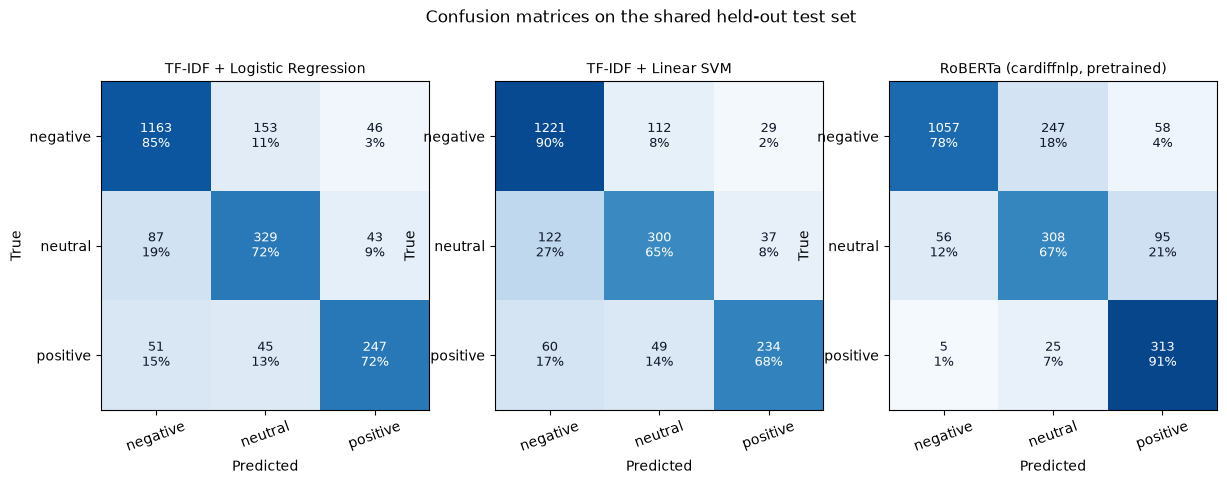

In [12]:
# 8.2 — Confusion matrices (rows = true class; cells = count + row-share). RQ2 evidence.
fig, axes = plt.subplots(1, len(results), figsize=(4.8 * len(results), 4.5))
axes = np.atleast_1d(axes)
for ax, (name, result) in zip(axes, results.items()):
    cm = result["confusion_matrix"]
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j] * 100:.0f}%", ha="center", va="center",
                    fontsize=9, color="white" if cm_norm[i, j] > 0.5 else "#0f172a")
    ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=20)
    ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices on the shared held-out test set", y=1.02)
fig.savefig(RESULTS_DIR / "fig_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Results

The tables and figures above are **computed live from this run** — no numbers are hard-coded anywhere in this notebook, so re-running updates every value. The comparison table in §8.1 answers **RQ1**; the confusion matrices in §8.2 answer **RQ2**.

What to look for when reading them:

- **Accuracy vs macro-F1 gap.** Under a 63% majority class, a model can score respectable accuracy while performing poorly on minority classes; the macro-F1 column is the balanced view, and the per-class table shows exactly where.
- **Per-class recall on *neutral* and *positive*.** Both classes are minority classes; their recall is where imbalanced training and fuzzy class boundaries bite. The confusion matrices show the classic *neutral↔negative* and *neutral↔positive* confusions for each model.
- **The two linear baselines** differ only in loss geometry (logistic vs hinge); if their confusion patterns differ materially, that is worth a second look in §10.
- **Timing** spans orders of magnitude by construction (a ~125M-parameter transformer vs a linear model on sparse features). It is reported per device and is not a quality claim.
- **Confidence analysis (§9.1)** is diagnostic only and uncalibrated — see §8.


,model,mean_confidence_correct,mean_confidence_incorrect,share_wrong_with_conf_above_0.9
0,TF-IDF + Logistic Regression,0.7680,0.5926,0.0188
1,"RoBERTa (cardiffnlp, pretrained)",0.8408,0.7174,0.1667


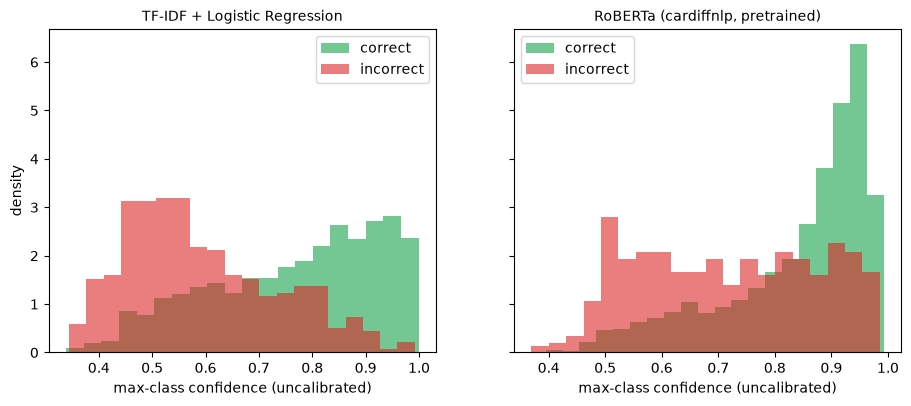

Reminder: these confidences are NOT calibrated probabilities (§8) — treat them as relative signals only.


In [13]:
# 9.1 — Confidence analysis (uncalibrated, diagnostic only; SVM excluded — no probabilities).
conf_lr = lr_clf.predict_proba(X_test_vec).max(axis=1)
conf_tx = probs_tx.max(axis=1)

confidence_rows = []
for model_name, conf, y_pred in [
    ("TF-IDF + Logistic Regression", conf_lr, y_pred_lr),
    ("RoBERTa (cardiffnlp, pretrained)", conf_tx, y_pred_tx),
]:
    correct = np.asarray(y_pred) == y_test
    confidence_rows.append({
        "model": model_name,
        "mean_confidence_correct": round(float(conf[correct].mean()), 4),
        "mean_confidence_incorrect": round(float(conf[~correct].mean()), 4),
        "share_wrong_with_conf_above_0.9": round(float((conf[~correct] > 0.9).mean()), 4) if (~correct).any() else 0.0,
    })

confidence_summary = pd.DataFrame(confidence_rows)
display(confidence_summary)
confidence_summary.to_csv(RESULTS_DIR / "confidence_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (model_name, conf, y_pred) in zip(
    axes,
    [("TF-IDF + Logistic Regression", conf_lr, y_pred_lr), ("RoBERTa (cardiffnlp, pretrained)", conf_tx, y_pred_tx)],
):
    correct = np.asarray(y_pred) == y_test
    ax.hist(conf[correct], bins=20, alpha=0.6, label="correct", color="#16a34a", density=True)
    ax.hist(conf[~correct], bins=20, alpha=0.6, label="incorrect", color="#dc2626", density=True)
    ax.set_title(model_name, fontsize=10)
    ax.set_xlabel("max-class confidence (uncalibrated)")
    ax.legend()
axes[0].set_ylabel("density")
fig.savefig(RESULTS_DIR / "fig_confidence.png", dpi=150, bbox_inches="tight")
plt.show()
print("Reminder: these confidences are NOT calibrated probabilities (§8) — treat them as relative signals only.")


## 10. Error analysis

**RQ3** is answered here. For each model, the tables below show the tweets it got **wrong** (sorted by its own confidence, i.e. its *most confidently wrong* predictions), with true and predicted labels. Every text appears exactly once in the test split (§6), so each error is a genuine model disagreement, not a duplicate record.

The same content is exported:
- `results/predictions_test.csv` — every test tweet with true label, each model's prediction and confidences, and **anonymised text** (`@handles → @user`, `URLs → http`).
- `results/error_analysis.csv` — the misclassified rows only.

Reading guidance: look for (a) **sarcasm and irony** — positive words wrapped around negative events ("thanks for losing my bag"); (b) **slang and abbreviations**; (c) **ambiguous or mixed sentiment** in a single short text; (d) **domain-anchored tokens** (airline names, flight numbers) that the crowd labellers weighed differently than either model. Both models failing on the *same* tweet suggests a labelling or ambiguity problem; disagreements suggest a modelling difference worth chasing.


In [14]:
# 10.1 — Build, display and export the error-analysis tables (anonymised text in exports).
def anonymise(text: str) -> str:
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"https?://\S+", "http", text)
    return text

test_eval = pd.DataFrame({
    "tweet_id": test_df["tweet_id"],
    "true": y_test,
    "pred_lr": y_pred_lr,
    "pred_svm": y_pred_svm,
    "pred_transformer": y_pred_tx,
    "conf_lr": conf_lr,
    "conf_transformer": conf_tx,
    "text": [anonymise(text) for text in test_df["text_raw"]],
})

wrong_any = (
    (test_eval["pred_lr"] != test_eval["true"])
    | (test_eval["pred_svm"] != test_eval["true"])
    | (test_eval["pred_transformer"] != test_eval["true"])
)
errors = test_eval[wrong_any].reset_index(drop=True)

def show_errors(frame, conf_col, pred_col, model_name, n=8):
    picked = frame.sort_values(conf_col, ascending=False).head(n)
    print(f"\nMost confidently wrong — {model_name} (top {n} of {len(frame):,} misclassified):")
    for _, row in picked.iterrows():
        snippet = row["text"][:150] + ("..." if len(row["text"]) > 150 else "")
        print(f"  true={row['true']:<8} pred={row[pred_col]:<8} conf={row[conf_col]:.2f} | {snippet}")

show_errors(test_eval[test_eval["pred_transformer"] != test_eval["true"]].reset_index(drop=True),
            "conf_transformer", "pred_transformer", "RoBERTa (cardiffnlp, pretrained)")
show_errors(test_eval[test_eval["pred_lr"] != test_eval["true"]].reset_index(drop=True),
            "conf_lr", "pred_lr", "TF-IDF + Logistic Regression")

lr_wrong = int((test_eval["pred_lr"] != test_eval["true"]).sum())
svm_wrong = int((test_eval["pred_svm"] != test_eval["true"]).sum())
tx_wrong = int((test_eval["pred_transformer"] != test_eval["true"]).sum())
both_wrong = int(((test_eval["pred_lr"] != test_eval["true"]) & (test_eval["pred_transformer"] != test_eval["true"])).sum())
print(f"\nMisclassified on the test set — LR: {lr_wrong:,} | SVM: {svm_wrong:,} | RoBERTa: {tx_wrong:,} | LR and RoBERTa share: {both_wrong:,}")
print(f"Exports: {RESULTS_DIR / 'predictions_test.csv'} ({len(test_eval):,} rows) | {RESULTS_DIR / 'error_analysis.csv'} ({len(errors):,} rows)")

test_eval.to_csv(RESULTS_DIR / "predictions_test.csv", index=False)
errors.to_csv(RESULTS_DIR / "error_analysis.csv", index=False)



Most confidently wrong — RoBERTa (cardiffnlp, pretrained) (top 8 of 486 misclassified):
  true=negative pred=positive conf=0.99 | @user Hooray! I've now been on hold for over an hour. I've never loved Southwest more.
  true=neutral  pred=positive conf=0.99 | @user !!!!! YAAYY!!! YAY PROM!!!! http
  true=neutral  pred=positive conf=0.98 | @user BTW, not a weather delay. We've had beautiful weather in Sunny California. #nolove #noexcuses #cali http
  true=negative pred=positive conf=0.98 | @user Flt 463 San Jose, CA -&gt; Denver, CO. Delayed 2 hrs but easily best flight + touchdown in all my years flying. Keep it up!
  true=neutral  pred=positive conf=0.98 | @user I digg it!
  true=neutral  pred=positive conf=0.98 | @user OMG OMG OMG !!! I JUST DID!!
  true=neutral  pred=positive conf=0.97 | @user we finally just arrive to Bogota, good but long flight!!
  true=neutral  pred=positive conf=0.97 | @user Thank you, you too!

Most confidently wrong — TF-IDF + Logistic Regression (top 8 of 42

## 11. Discussion

**Sarcasm and irony.** Airline Twitter traffic is saturated with polite-surface hostility ("Thanks @Airline for destroying my suitcase"). Both a lexical model and a sentiment-pretrained transformer read the *words* first; the crowd labellers read the *event*. Expect the shared-error count in §10 to be dominated by such cases — that is a property of the annotation construct as much as of the models.

**Slang, abbreviation and register.** 2015 Twitter English ("smh", "u", truncated clauses, emoji chains) sits awkwardly with TF-IDF's token statistics; the transformer's pretraining corpus (2018–2021 tweets) overlaps this register better in style, though not in time — a temporal mismatch that is itself instructive.

**Ambiguous wording.** Short mixed-sentiment texts ("Long delay but the crew was lovely") straddle class boundaries; *neutral* absorbs much of this ambiguity, which is visible as neutral↔negative and neutral↔positive confusions in §8.2 and as low *neutral* recall.

**Domain bias.** Mentions of airline handles, flight numbers and airport names anchor the models to this domain. The crowd labels encode aviation-specific expectations (delays, fees, upgrades); a model transferred to another vertical inherits nothing of that, and TF-IDF's vocabulary is entirely domain-specific by construction.

**Class imbalance.** With ~63% negative examples, class weighting (both linear models) and a balanced pretraining diet (the transformer's TweetEval fine-tuning) both push recall toward minority classes at some cost to majority precision — the per-class tables make the trade visible. Macro-F1 is the honest headline under imbalance; accuracy flatters whichever model leans into the majority.

**Transformer vs classical — the honest framing.** The transformer starts with 124M tweets of domain-relevant pretraining paid for upstream; the linear model learns from ~10k local tweets in seconds. That the comparison is even close (see the live table) says as much about the small dataset and the three-class crowd labels as about the architectures. On this evidence, a practitioner picks the transformer for its generalisation and recall on minority classes, and the linear model for transparency, speed and auditability — *on this dataset*, which generalises no further than its February-2015, US-airlines, Twitter origin.


## 12. Limitations and threats to validity

**Construct validity.** The three-class labels are crowd judgements on subjective short texts; *neutral* in particular is a catch-all. The per-annotation confidence field (`airline_sentiment_confidence`) is unused here, so label noise is unmeasured in this notebook.

**Internal validity.**
- *Preprocessing asymmetry*: the transformer receives model-card-normalised text while TF-IDF receives whitespace-collapsed raw text. Each model gets its documented correct input, but the systems under comparison differ in more than their parameters.
- *Small tuning scope*: only `C` is tuned, on a 5-point grid; both linear baselines could be pushed further (features, thresholding — thresholds were deliberately **not** tuned on the test set).
- *Single split, single run*: one stratified split at seed 42, no repeated splits, no confidence intervals. The deterministic seeds make the run reproducible, not statistically comprehensive.

**External validity.** One dataset, one platform, one language, one month (February 2015), one domain (US airlines). **Nothing here generalises to other platforms, topics or eras** — and the transformer's pretraining period (2018–2021) does not overlap the evaluation year, a temporal mismatch shared by both models.

**Statistical and measurement caveats.** Reported timing is hardware-dependent and not a quality metric; confidences are uncalibrated (§8, §9.1); metrics carry no uncertainty estimates.

**Reproducibility boundaries.** The notebook pins seeds, records versions and dataset checksum, and saves all artifacts — but exact transformer behaviour can still vary slightly with library versions, hardware and model-repository updates. The version snapshot in `results/environment_report.csv` is the authoritative record of the run that produced these outputs.


## 13. Conclusion and future work

**What this notebook delivers.** A compact, leakage-safe, fully scripted comparison of a classical TF-IDF pipeline (class-weighted Logistic Regression + Linear SVM) and a pretrained social-media transformer on one documented, imbalanced dataset — evaluated once on a shared held-out test set with class-aware metrics, confusion matrices, exported error analysis and a packaged results archive. The answers to RQ1–RQ3 are the live tables in §8–§10 of this run; by construction they cannot be stated in advance or quoted out of execution.

**What it does not claim.** No novelty, no state-of-the-art claim, no generalisation beyond this dataset, and no claim that the pretrained model was trained here — it was used exactly as published.

**Future work.**
1. Multi-dataset, multi-platform evaluation (e.g. other TweetEval tasks, Reddit, product reviews) with paired per-dataset reporting.
2. Probability calibration (temperature scaling fit on validation) so the confidence analysis reports *calibrated* probabilities.
3. A small fine-tuning experiment on a GPU runtime, comparing the out-of-the-box transformer against its locally fine-tuned self.
4. Uncertainty over splits: repeated stratified splits with bootstrap confidence intervals on macro-F1.
5. Sarcasm-targeted evaluation sets to test the shared-error hypothesis of §11 directly.


## 14. References

All URLs were verified at the time of writing. Citations are to sources actually used by this notebook; none are decorative.

1. CrowdFlower (2016). *Twitter US Airline Sentiment* [Data set]. Kaggle. https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment — licensed **CC BY-NC-SA 4.0** (verified on the dataset page).
2. Loureiro, D., Barbieri, F., Neves, L., Espinosa-Anke, L., & Camacho-Collados, J. (2022). TimeLMs: Diachronic Language Models from Twitter. *Proceedings of ACL 2022: System Demonstrations*. https://aclanthology.org/2022.acl-demo.25/ (arXiv:2202.03829) — the paper introducing the `twitter-roberta-base-sentiment-latest` model.
3. Barbieri, F., Camacho-Collados, J., Neves, L., & Espinosa-Anke, L. (2020). TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification. *Findings of EMNLP 2020*. https://arxiv.org/abs/2010.12421 — the sentiment benchmark the model is fine-tuned on.
4. Cardiff NLP. *Model card: `cardiffnlp/twitter-roberta-base-sentiment-latest`*. https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest — source of the label mapping, preprocessing instructions and training-corpus description used in §6–§7.
5. Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
6. Paszke, A., Gross, S., Massa, F., et al. (2019). PyTorch: An Imperative Style, High-Performance Deep Learning Library. *Advances in Neural Information Processing Systems 32 (NeurIPS 2019)*.
7. Wolf, T., Debut, L., Sanh, V., et al. (2020). Transformers: State-of-the-Art Natural Language Processing. *Proceedings of EMNLP 2020: System Demonstrations*. https://aclanthology.org/2020.emnlp-demos.6/
8. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference (SciPy 2010)*.


In [15]:
# 15 — Run summary, environment report, and results archive.
environment_rows = [
    ("run_started_at_utc", RUN_STARTED_AT),
    ("run_finished_at_utc", datetime.now(timezone.utc).isoformat(timespec="seconds")),
    ("python", VERSIONS["python"]),
    ("platform", VERSIONS["platform"]),
    ("numpy", VERSIONS["numpy"]),
    ("pandas", VERSIONS["pandas"]),
    ("scikit-learn", VERSIONS["scikit-learn"]),
    ("torch", VERSIONS["torch"]),
    ("transformers", VERSIONS["transformers"]),
    ("device", str(DEVICE)),
    ("gpu_name", HARDWARE["gpu_name"] or "none (CPU fallback)"),
    ("cpu_count", os.cpu_count()),
    ("random_seed", SEED),
    ("dataset_source", DATASET_URL),
    ("dataset_sha256", DATA_SHA256),
    ("dataset_source_mode", data_source_mode),
    ("dataset_licence", DATASET_LICENCE),
    ("transformer_model_id", MODEL_ID),
    ("transformer_model_card", MODEL_CARD_URL),
    ("label_mapping_class_to_model_index", json.dumps(MODEL_INDEX)),
    ("split_fractions", f"train={TRAIN_FRACTION} / val={VAL_FRACTION} / test={TEST_FRACTION} (stratified)"),
    ("n_train", len(train_df)),
    ("n_validation", len(val_df)),
    ("n_test", len(test_df)),
    ("logreg_C_selected_on_validation", BEST_C),
]
pd.DataFrame(environment_rows, columns=["key", "value"]).to_csv(RESULTS_DIR / "environment_report.csv", index=False)

print("Generated outputs:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"  {path.name:<40} {path.stat().st_size / 1024:9.1f} KB")

zip_path = shutil.make_archive("results_bundle", "zip", root_dir=RESULTS_DIR)
print(f"\nArchive written: {zip_path}")

try:
    from google.colab import files  # type: ignore[import]
    files.download(zip_path)
except ImportError:
    print("(Not running in Colab — download the archive manually if you need it.)")

print("\n=== Experiment summary ===")
print(f"  Dataset    : Twitter US Airline Sentiment ({len(raw_df):,} rows, sha256 {DATA_SHA256[:12]}...) - {DATASET_LICENCE.split(' (')[0]}")
print(f"  Split      : train {len(train_df):,} / validation {len(val_df):,} / test {len(test_df):,} (stratified, seed {SEED}, disjoint)")
print(f"  Models     : TF-IDF + Logistic Regression (C={BEST_C}), TF-IDF + Linear SVM, RoBERTa (cardiffnlp, pretrained, not fine-tuned)")
print(f"  Evaluation : all models scored once on the SAME {len(test_df):,} test examples")
print(f"  Metrics    : {RESULTS_DIR / 'comparison_metrics.csv'} | figures, reports and the error-analysis CSV sit beside it")
print("  All numbers above were computed live by this run — nothing is hard-coded.")


Generated outputs:
  c_sweep_validation.csv                         0.1 KB
  classification_report_logreg.txt               0.4 KB
  classification_report_roberta.txt              0.4 KB
  classification_report_svm.txt                  0.4 KB
  comparison_metrics.csv                         0.3 KB
  confidence_summary.csv                         0.2 KB
  eda_summary.csv                                0.1 KB
  environment_report.csv                         1.1 KB
  error_analysis.csv                           129.7 KB
  fig_class_distribution.png                    24.9 KB
  fig_confidence.png                            47.3 KB
  fig_confusion_matrices.png                   122.1 KB
  fig_text_lengths.png                          33.7 KB
  inference_timing.csv                           0.2 KB
  per_class_metrics.csv                          0.9 KB
  predictions_test.csv                         383.9 KB
  split_summary.csv                              0.1 KB

Archive written: /app/build/